# 5.5.3 — Florestas Públicas: tabela por unidade e mapas de detalhe

**Objetivo:** responder aos pedidos do orientador com a tabela completa por floresta pública, mapa geral com contornos fortes, mapa da UF com mais registros e mapas das duas unidades com mais registros. Os caminhos da versão 2 já estão preenchidos.

**Como usar:** abra no Google Colab e selecione **Ambiente de execução → Executar tudo**. Autorize a montagem do Drive. A primeira execução precisa percorrer um CSV de aproximadamente **20,9 GB**, mesmo lendo uma linha de cada vez; pode demorar. O notebook cria um cache reduzido e reutilizável, sem copiar o CSV integral para a memória. Mantenha a sessão ativa. O ZIP final contém tabelas, mapas e textos para revisão do subcapítulo; o cache fica fora do ZIP.

**Critérios de leitura:** caso = linha da base espacial V2; não equivale a produtor, contrato ou irregularidade. Os IDs internos distinguem unidades com o mesmo nome. Nenhum registro é eliminado por repetição de gleba ou REF_BACEN. Os mapas distinguem **limite da floresta (azul), gleba completa (laranja) e interseção (vermelho)**. Somente florestas com ocorrência na amostra são representadas.

Nos resumos V2 conferidos em 18/09/2026, Goiás tem mais registros (7.232), e as duas primeiras unidades são APA Serra da Ibiapaba (1.417) e APA Ilha do Bananal/Cantão (1.065). **São referências de conferência:** o notebook recalcula os rankings, sem fixar a seleção. O ranking estadual usa a localização das interseções e pode apresentar pequenas diferenças em relação ao resumo baseado em partes municipais.

A geometria integral das unidades fica no cache. Nos mapas de visão geral e estadual, apenas o desenho é simplificado para reduzir o peso; os cálculos e os mapas individuais usam a precisão original. Os campos de tipo são mantidos literalmente, sem atribuir situação jurídica não documentada.

## 1. Preparar o Colab e montar o Drive

In [1]:
%pip -q install "geopandas>=1.0,<2" "shapely>=2.0,<3" "pyogrio>=0.9" "pyproj>=3.6" openpyxl requests tqdm
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Caminhos e parâmetros
A origem é a base de registros espaciais, não a base expandida por partes municipais. Se os arquivos forem movidos, altere apenas os caminhos abaixo. O CRS do WKT deve corresponder ao usado na versão 2.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
RAIZ = Path('/content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios')
PASTA_V2 = RAIZ / 'intersecoes' / 'florestas publicas' / 'resultados_por_id_gleba2' / 'versao_2'
ARQUIVO_BASE = PASTA_V2 / 'bases_analiticas' / 'base_registros_espaciais_sem_deduplicacao.csv'
ID_DRIVE_BASE = '10q-efCrT-DgTfM2tUgUvSV5KaNyaV3sS'
ARQUIVO_UFS = None       # opcional: caminho de ZIP, SHP, GPKG ou GeoJSON
ARQUIVO_BIOMAS = None    # opcional: caminho de ZIP, SHP, GPKG ou GeoJSON
FONTE_UFS = 'IBGE, Malha de Unidades da Federação, 2024'
FONTE_BIOMAS = 'IBGE, Biomas do Brasil, 2019, escala 1:250.000'
URL_UFS = 'https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2024/Brasil/BR_UF_2024.zip'
URL_BIOMAS = 'https://geoftp.ibge.gov.br/informacoes_ambientais/estudos_ambientais/biomas/vetores/Biomas_250mil.zip'
COLUNA_UF = 'SIGLA_UF'
COLUNA_BIOMA = 'Bioma'
CRS_WKT = 'EPSG:4674'
CRS_ANALISE = 'EPSG:5880'
ANOS = [2021, 2022, 2023, 2024, 2025]
NUMERO_TERRITORIOS_DETALHE = 2
DPI = 400
FORMATOS = ['png', 'pdf', 'svg']
MOSTRAR_FIGURAS = True
BAIXAR_ZIP = True
TOLERANCIA_AREA_HA = 0.05
REFERENCIA = dict(registros=33984,glebas=25284,territorios=1766,refs=25864,
    area_acumulada_ha=445302.3382645251,area_uniao_ha=232002.77528966122,
    soma_valores_linhas=12321219185.590002)
# Descoberta automática da coluna com o polígono completo da floresta.
# Preencha somente se o notebook informar mais de uma candidata.
COLUNA_GEOMETRIA_FLORESTA = None
SIMPLIFICACAO_GERAL_M = 150
SIMPLIFICACAO_ESTADO_M = 30
RECRIAR_CACHE = False
VERSAO_CACHE = 'fp553_v1'
EXECUCAO = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
SAIDA = RAIZ / 'complementos_florestas_publicas_5_5_3' / EXECUCAO
CACHE = RAIZ / 'complementos_florestas_publicas_5_5_3' / '_cache'
for p in [SAIDA,CACHE,SAIDA/'tabelas',SAIDA/'mapas']:p.mkdir(parents=True,exist_ok=True)
print('Base:',ARQUIVO_BASE)
print('Resultados:',SAIDA)

ARQUIVO_RESUMO_UNIDADES = PASTA_V2 / 'tabelas' / '04_resumo_por_unidade_territorial.csv'


Base: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/intersecoes/florestas publicas/resultados_por_id_gleba2/versao_2/bases_analiticas/base_registros_espaciais_sem_deduplicacao.csv
Resultados: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_florestas_publicas_5_5_3/20260918_124912_005341


## 3. Contexto cartográfico
Limites de UFs e bioma são obtidos do IBGE. São preservados os polígonos das florestas da versão 2, evitando misturar versões territoriais. O arquivo grande é identificado por caminho, tamanho e data de modificação; não é relido apenas para calcular um hash integral.

In [3]:
import json, hashlib, zipfile, re, math, platform, textwrap
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
from pyproj import CRS, Transformer, Geod
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from IPython.display import display
ORIGENS={}

def hash_arquivo(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

def entrada_drive():
    if not ARQUIVO_BASE.is_file():
        raise FileNotFoundError('Base não encontrada no Drive montado: '+str(ARQUIVO_BASE)+
            '\nConfira a conta e o caminho. ID do arquivo conferido: '+ID_DRIVE_BASE)
    return ARQUIVO_BASE

def obter_vetor(local,url,nome):
    if local:
        p=Path(local)
        if not p.is_file():raise FileNotFoundError(p)
        return p
    p=CACHE/nome
    if not (p.is_file() and zipfile.is_zipfile(p)):
        tmp=p.with_suffix('.part')
        with requests.get(url,stream=True,timeout=(30,180)) as r:
            r.raise_for_status()
            with tmp.open('wb') as f:
                for b in r.iter_content(1024*1024):f.write(b)
        if not zipfile.is_zipfile(tmp):raise ValueError('O download não retornou ZIP: '+url)
        tmp.replace(p)
    return p

def ler_vetor(p):
    z=gpd.read_file('zip://'+str(p) if str(p).lower().endswith('.zip') else p)
    if z.crs is None:raise ValueError('Vetor sem referência espacial: '+str(p))
    return z

CAMINHO=entrada_drive()
pufs=obter_vetor(ARQUIVO_UFS,URL_UFS,'BR_UF_2024.zip')
pbiomas=obter_vetor(ARQUIVO_BIOMAS,URL_BIOMAS,'Biomas_250mil_2019.zip')
for nome,p in [('base',CAMINHO),('ufs',pufs),('biomas',pbiomas)]:
    ORIGENS[nome]={'arquivo':str(p),'bytes':p.stat().st_size,'mtime_ns':p.stat().st_mtime_ns}
    if nome!='base':ORIGENS[nome]['sha256']=hash_arquivo(p)
ufs=ler_vetor(pufs);biomas=ler_vetor(pbiomas)
if COLUNA_UF not in ufs or COLUNA_BIOMA not in biomas:raise ValueError('Confira as colunas dos arquivos de contexto.')
ufs=ufs[[COLUNA_UF,'geometry']].rename(columns={COLUNA_UF:'UF'}).to_crs(CRS_ANALISE)
ufs['UF']=ufs.UF.astype(str).str.strip()
if ufs.UF.duplicated().any():ufs=ufs.dissolve(by='UF',as_index=False)
cer=biomas.loc[biomas[COLUNA_BIOMA].astype(str).str.strip().str.casefold().eq('cerrado'),['geometry']].to_crs(CRS_ANALISE)
if cer.empty:raise ValueError('Cerrado não encontrado no vetor de biomas.')
# Reparos apenas nos limites de contexto; qualquer alteração fica registrada.
ORIGENS['reparos_contexto']={}
for nome,z in [('ufs',ufs),('cerrado',cer)]:
    if z.geometry.isna().any() or z.geometry.is_empty.any():raise ValueError('Geometria ausente no contexto '+nome)
    mask=~z.is_valid;ORIGENS['reparos_contexto'][nome]=int(mask.sum())
    if mask.any():z.loc[mask,'geometry']=z.loc[mask,'geometry'].make_valid()
    if not z.geom_type.isin(['Polygon','MultiPolygon']).all():raise ValueError('Contexto não poligonal: '+nome)
cerrado=cer.geometry.union_all()
print('Entradas localizadas. Base:',round(CAMINHO.stat().st_size/1e9,2),'GB; leitura sequencial na próxima célula.')


Entradas localizadas. Base: 20.92 GB; leitura sequencial na próxima célula.


## 4. Ler a base grande com memória controlada e validar geometrias

A leitura é sequencial pelo módulo `csv`, respeitando aspas e campos WKT extensos. O cache SQLite guarda uma cópia de cada geometria de floresta/gleba e **todas as linhas de interseção**. Cada identificador repetido é conferido: cópias diferentes precisam ser geometricamente equivalentes. Ausência de geometria, WKT inválido, divergência entre cópias ou ano fora do período interrompe a execução com diagnóstico; nada é excluído ou corrigido silenciosamente.

A base original tem cerca de 20,9 GB por repetir polígonos extensos. Somente a cópia necessária a cada processamento fica em memória durante a leitura. Depois, permanecem as interseções e as versões de desenho das geometrias únicas. O cache é validado pelo tamanho e data de modificação da origem, CRS e versão do leitor; use `RECRIAR_CACHE=True` após substituir manualmente uma origem preservando esses atributos.

In [5]:
import csv as csvmod, sqlite3, zlib, tempfile, shutil, time
from shapely.ops import transform as transformar
from tqdm.auto import tqdm
csvmod.field_size_limit(2**31-1)

def numero_pt(v):
    s=str(v).strip()
    if s.lower() in ['', 'nan', 'none', 'null', '<na>']:return np.nan
    if ',' in s:s=s.replace('.','').replace(',','.')
    try:
        a=float(s)
        if not np.isfinite(a):raise ValueError(s)
        return a
    except ValueError:raise ValueError('Número não interpretável: '+s)

def csv(t,n):
    t.to_csv(SAIDA/'tabelas'/n,index=False,sep=';',decimal=',',encoding='utf-8-sig',float_format='%.9f')

with CAMINHO.open('r',encoding='utf-8-sig',newline='') as f:
    cabecalho=next(csvmod.reader(f,delimiter=';'))
if len(cabecalho)!=len(set(cabecalho)):raise ValueError('Há nomes de colunas duplicados no CSV.')
C={'gleba':'ID_GLEBA2','ref':'REF_BACEN','ano':'ANO_BASE','unidade':'FP_ID_INTERNO',
   'nome':'FP_NOME','tipo':'FP_TIPO','uf_territorio':'FP_UF','valor':'VL_PARC_CREDITO',
   'area_csv':'AREA_INTERSECAO_HA','inter':'GEOMETRIA_INTERSECAO_WKT','geom_gleba':'GT_GEOMETRIA'}
# Campos administrativos conferidos no arquivo 01_campos_identificados.csv da V2.
# A geometria territorial completa é descoberta no cabeçalho sem carregar os 20,9 GB.
if COLUNA_GEOMETRIA_FLORESTA:
    C['geom_territorio']=COLUNA_GEOMETRIA_FLORESTA
else:
    conhecidas=['GEOMETRIA_FLORESTA_PUBLICA_WKT','GEOMETRIA_FLORESTA_WKT','GEOMETRIA_FP_WKT',
                'GEOMETRIA_CNFP_WKT','FP_GEOMETRIA_WKT','FP_GEOMETRIA','CNFP_GEOMETRIA']
    candidatas=[c for c in cabecalho if c in conhecidas or
        ('GEOMETR' in c.upper() and any(t in c.upper() for t in ['FLORESTA','CNFP','FP_','_FP']))]
    candidatas=list(dict.fromkeys(candidatas))
    if len(candidatas)!=1:
        (SAIDA/'cabecalho_base.txt').write_text('\n'.join(cabecalho),encoding='utf-8')
        raise ValueError('Não foi possível selecionar uma única geometria COMPLETA da floresta. '
            'Candidatas: '+str(candidatas)+'. Veja cabecalho_base.txt e preencha COLUNA_GEOMETRIA_FLORESTA. '
            'Não use GEOMETRIA_INTERSECAO_WKT em seu lugar.')
    C['geom_territorio']=candidatas[0]
C['linha']='_ID_LINHA_ORIGINAL' if '_ID_LINHA_ORIGINAL' in cabecalho else None
faltam=set(v for v in C.values() if v)-set(cabecalho)
if faltam:raise ValueError('Colunas obrigatórias ausentes: '+str(sorted(faltam)))
if C['geom_territorio'] in [C['inter'],C['geom_gleba']]:raise ValueError('Coluna da floresta não pode ser a interseção ou a gleba.')
ORIGENS['identificador_linha']=C['linha'] or 'posição sequencial no CSV de registros espaciais'
assinatura={'origem':ORIGENS['base'],'colunas':C,'anos':ANOS,'crs_wkt':CRS_WKT,
            'crs_analise':CRS_ANALISE,'versao':VERSAO_CACHE}
chave=hashlib.sha256(json.dumps(assinatura,sort_keys=True).encode()).hexdigest()[:20]
BANCO=CACHE/f'florestas_reduzido_{chave}.sqlite'
converter=Transformer.from_crs(CRS_WKT,CRS_ANALISE,always_xy=True).transform

# def poligono(wkt,identificacao):
#     if not str(wkt).strip():raise ValueError('Geometria ausente: '+identificacao)
#     g=shapely.force_2d(shapely.from_wkt(wkt,on_invalid='raise'))
#     if g is None or g.is_empty or g.geom_type not in ('Polygon','MultiPolygon'):
#         raise ValueError('Geometria vazia ou não poligonal: '+identificacao)
#     if not g.is_valid:raise ValueError('Geometria inválida: '+identificacao+'; '+shapely.is_valid_reason(g))
#     a,b,c,d=g.bounds
#     if not all(np.isfinite([a,b,c,d])):raise ValueError('Coordenadas não finitas: '+identificacao)
#     if CRS.from_user_input(CRS_WKT).is_geographic and not (-80<a<-30 and -40<b<10 and -80<c<-30 and -40<d<10):
#         raise ValueError('Coordenadas incompatíveis com WKT geográfico do Brasil: '+identificacao)
#     g=transformar(converter,g)
#     if not g.is_valid or not np.isfinite(g.area) or g.area<=0:
#         raise ValueError('Geometria problemática após reprojeção: '+identificacao)
#     return g

def poligono(wkt, identificacao):
    if not str(wkt).strip():
        raise ValueError('Geometria ausente: ' + identificacao)

    g = shapely.force_2d(
        shapely.from_wkt(wkt, on_invalid='raise')
    )

    if (
        g is None
        or g.is_empty
        or g.geom_type not in ('Polygon', 'MultiPolygon')
    ):
        raise ValueError(
            'Geometria vazia ou não poligonal: ' + identificacao
        )

    if not g.is_valid:
        raise ValueError(
            'Geometria inválida na origem: '
            + identificacao + '; '
            + shapely.is_valid_reason(g)
        )

    a, b, c, d = g.bounds

    if not np.isfinite([a, b, c, d]).all():
        raise ValueError(
            'Coordenadas não finitas: ' + identificacao
        )

    if CRS.from_user_input(CRS_WKT).is_geographic:
        if not (
            -80 < a < -30 and -40 < b < 10
            and -80 < c < -30 and -40 < d < 10
        ):
            raise ValueError(
                'Coordenadas incompatíveis com o CRS geográfico: '
                + identificacao
            )

    g = transformar(converter, g)

    if not np.isfinite(g.bounds).all() or not np.isfinite(g.area):
        raise ValueError(
            'Reprojeção produziu coordenadas ou área não finitas: '
            + identificacao
            + '. Confira CRS_WKT e CRS_ANALISE.'
        )

    if not g.is_valid:
        motivo = shapely.is_valid_reason(g)

        # Somente limites utilizados para desenho podem ser reparados.
        permite_reparo = identificacao.startswith(
            ('territorio=', 'gleba=')
        )

        if not permite_reparo:
            raise ValueError(
                'Interseção inválida após reprojeção: '
                + identificacao + '; ' + motivo
            )

        area_antes = float(g.area)
        corrigida = shapely.make_valid(g)

        # Extrai apenas componentes poligonais do resultado.
        pendentes = [corrigida]
        poligonos = []
        descartados = []

        while pendentes:
            parte = pendentes.pop()

            if parte.is_empty:
                continue

            if parte.geom_type == 'Polygon':
                poligonos.append(parte)

            elif parte.geom_type in (
                'MultiPolygon', 'GeometryCollection'
            ):
                pendentes.extend(parte.geoms)

            else:
                descartados.append(parte.geom_type)

        if not poligonos:
            raise ValueError(
                'Reparo não recuperou polígonos: ' + identificacao
            )

        g = shapely.union_all(poligonos)

        if (
            g.is_empty
            or not g.is_valid
            or g.geom_type not in ('Polygon', 'MultiPolygon')
            or not np.isfinite(g.area)
            or g.area <= 0
        ):
            raise ValueError(
                'Geometria não recuperável após reprojeção: '
                + identificacao
            )

        registro = {
            'identificacao': identificacao,
            'motivo': motivo,
            'procedimento': 'make_valid após reprojeção',
            'finalidade': 'limite para representação cartográfica',
            'area_antes_ha': area_antes / 10000,
            'area_depois_ha': float(g.area) / 10000,
            'diferenca_area_ha': (float(g.area) - area_antes) / 10000,
            'componentes_nao_poligonais_descartados': descartados
        }

        arquivo = SAIDA / 'reparos_geometrias_desenho.jsonl'

        with arquivo.open('a', encoding='utf-8') as f:
            f.write(
                json.dumps(registro, ensure_ascii=False) + '\n'
            )

        print(
            f'Reparo cartográfico registrado: {identificacao}; '
            f'motivo: {motivo}'
        )

    if g.is_empty or g.area <= 0:
        raise ValueError(
            'Geometria sem área positiva após reprojeção: '
            + identificacao
        )

    return g

def compactar(g):return sqlite3.Binary(zlib.compress(shapely.to_wkb(g),level=1))
def descompactar(v):return shapely.from_wkb(zlib.decompress(v))

def cache_pronto(p):
    if not p.is_file():return False
    try:
        with sqlite3.connect(p) as db:
            r=db.execute('SELECT valor FROM meta WHERE chave="assinatura"').fetchone()
            ok=db.execute('SELECT valor FROM meta WHERE chave="completo"').fetchone()
            return r is not None and json.loads(r[0])==assinatura and ok is not None and ok[0]=='sim'
    except (sqlite3.Error,ValueError):return False

def construir_cache(origem,destino):
    vistos={};atributos_vistos={};linhas_vistas=set();variantes=0
    inicio=time.monotonic();numero=0;linha_id=None;unidade=None;gleba=None
    # Banco intermediário em disco local: evita milhares de pequenas escritas no Drive.
    with tempfile.TemporaryDirectory(prefix='florestas_553_') as td:
        temporario=Path(td)/'cache.sqlite'
        db=sqlite3.connect(temporario)
        try:
            db.executescript('''
                CREATE TABLE geometrias (tipo TEXT, id TEXT, atributos TEXT, wkb BLOB, PRIMARY KEY(tipo,id));
                CREATE TABLE registros (numero INTEGER PRIMARY KEY, atributos TEXT, wkb BLOB);
                CREATE TABLE meta (chave TEXT PRIMARY KEY, valor TEXT);
            ''')
            def guardar_unica(tipo,ident,wkt,attrs):
                nonlocal variantes
                key=(tipo,ident);h=hashlib.sha256(wkt.encode('utf-8')).hexdigest()
                attrs_str=json.dumps(attrs,sort_keys=True,ensure_ascii=False)
                if key in vistos:
                    if atributos_vistos[key]!=attrs_str:raise ValueError('Atributos divergentes para '+tipo+'='+ident)
                    if h in vistos[key]:return
                    original=descompactar(db.execute('SELECT wkb FROM geometrias WHERE tipo=? AND id=?',key).fetchone()[0])
                    if not original.equals(poligono(wkt,tipo+'='+ident)):
                        raise ValueError('Cópias geométricas divergentes para '+tipo+'='+ident)
                    vistos[key].add(h);variantes+=1;return
                g=poligono(wkt,tipo+'='+ident)
                db.execute('INSERT INTO geometrias VALUES (?,?,?,?)',(tipo,ident,attrs_str,compactar(g)))
                vistos[key]={h};atributos_vistos[key]=attrs_str
            with origem.open('r',encoding='utf-8-sig',newline='') as f:
                reader=csvmod.DictReader(f,delimiter=';')
                for numero,row in enumerate(tqdm(reader,total=REFERENCIA['registros'],desc='Leitura sequencial',unit='linha'),1):
                    if None in row or any(v is None for v in row.values()):raise ValueError('Quantidade de campos diferente do cabeçalho.')
                    attrs={k:str(row[v]).strip() for k,v in C.items() if v and k not in ('inter','geom_gleba','geom_territorio','valor','area_csv')}
                    linha_id=attrs.get('linha',str(numero));attrs['linha']=linha_id
                    for k in ['linha','unidade','gleba','ref','ano']:
                        if attrs[k].lower() in ('','nan','none','null','<na>'):raise ValueError('Identificador ausente: '+k)
                    unidade=attrs['unidade'];gleba=attrs['gleba']
                    if linha_id in linhas_vistas:raise ValueError('ID de linha repetido; confira se a origem é a base de partes municipais.')
                    linhas_vistas.add(linha_id)
                    ano=numero_pt(attrs['ano'])
                    if ano not in ANOS:raise ValueError('Ano fora de 2021–2025: '+attrs['ano'])
                    attrs['ano']=str(int(ano));attrs['codigo_territorio']=unidade
                    for k in ['nome','tipo','uf_territorio']:
                        if attrs[k].lower() in ('','nan','none','null','<na>'):
                            attrs[k]='Sem denominação — ID '+unidade if k=='nome' else 'Não informado'
                    for campo_epsg in ['FP_EPSG','CNFP_EPSG']:
                        if campo_epsg in row and str(row[campo_epsg]).strip():
                            if numero_pt(row[campo_epsg])!=CRS.from_user_input(CRS_WKT).to_epsg():
                                raise ValueError(campo_epsg+' diverge do CRS_WKT configurado.')
                    attrs['valor']=numero_pt(row[C['valor']]);attrs['area_csv']=numero_pt(row[C['area_csv']])
                    if not np.isfinite(attrs['area_csv']):raise ValueError('Área de origem ausente.')
                    attrs_territorio={k:attrs[k] for k in ['unidade','codigo_territorio','nome','tipo','uf_territorio']}
                    guardar_unica('territorio',unidade,row[C['geom_territorio']],attrs_territorio)
                    guardar_unica('gleba',gleba,row[C['geom_gleba']],{'gleba':gleba})
                    g=poligono(row[C['inter']],'interseção, linha '+linha_id)
                    attrs['area_ha']=g.area/10000
                    db.execute('INSERT INTO registros VALUES (?,?,?)',(numero,json.dumps(attrs,ensure_ascii=False),compactar(g)))
                    if numero%500==0:db.commit()
            if numero==0:raise ValueError('Base vazia.')
            info={'linhas':numero,'variantes_wkt_equivalentes':variantes,'duracao_segundos':time.monotonic()-inicio}
            for k,v in [('assinatura',json.dumps(assinatura)),('completo','sim'),('leitura',json.dumps(info))]:
                db.execute('INSERT INTO meta VALUES (?,?)',(k,v))
            db.commit()
            if db.execute('PRAGMA quick_check').fetchone()[0]!='ok':raise RuntimeError('Falha na integridade do cache.')
        except Exception as exc:
            diagnostico={'linha_sequencial':numero,'linha_id':linha_id,'unidade':unidade,'gleba':gleba,'erro':str(exc)}
            (SAIDA/'diagnostico_leitura.json').write_text(json.dumps(diagnostico,ensure_ascii=False,indent=2),encoding='utf-8')
            raise
        finally:db.close()
        incompleto=destino.with_suffix('.part')
        shutil.copyfile(temporario,incompleto)
        if incompleto.stat().st_size!=temporario.stat().st_size:raise RuntimeError('Cópia incompleta do cache.')
        incompleto.replace(destino)
    print('Cache reduzido salvo:',destino,'—',round(destino.stat().st_size/1e6,1),'MB')

if RECRIAR_CACHE or not cache_pronto(BANCO):construir_cache(CAMINHO,BANCO)
else:print('Reutilizando cache concluído e compatível:',BANCO.name)

def carregar_geometrias(tipo,ids=None,simplificar=0):
    escolhidos=None if ids is None else set(map(str,ids));result=[]
    with sqlite3.connect(BANCO) as db:
        # Filtra por ID antes de descompactar geometrias não solicitadas.
        for ident,attrs,wkb in db.execute('SELECT id,atributos,wkb FROM geometrias WHERE tipo=?',(tipo,)):
            if escolhidos is not None and ident not in escolhidos:continue
            g=descompactar(wkb)
            if simplificar:g=g.simplify(simplificar,preserve_topology=True)
            result.append({**json.loads(attrs),'geometry':g})
    if not result:return gpd.GeoDataFrame({'geometry':[]},crs=CRS_ANALISE)
    return gpd.GeoDataFrame(result,geometry='geometry',crs=CRS_ANALISE)

reg=[]
with sqlite3.connect(BANCO) as db:
    for attrs,wkb in db.execute('SELECT atributos,wkb FROM registros ORDER BY numero'):
        reg.append({**json.loads(attrs),'geometry':descompactar(wkb)})
    ORIGENS['leitura_cache']=json.loads(db.execute('SELECT valor FROM meta WHERE chave="leitura"').fetchone()[0])
x=gpd.GeoDataFrame(reg,geometry='geometry',crs=CRS_ANALISE);del reg
# Estas duas coleções servem apenas ao desenho de visão geral; os originais estão no cache.
territorios=carregar_geometrias('territorio',simplificar=SIMPLIFICACAO_GERAL_M)
glebas=carregar_geometrias('gleba',simplificar=SIMPLIFICACAO_GERAL_M)
area_check=x[['linha','unidade','gleba','area_csv','area_ha']].copy()
area_check['diferenca_ha']=area_check.area_ha-area_check.area_csv
csv(area_check,'conferencia_areas_por_linha.csv')
if area_check.diferenca_ha.abs().max()>TOLERANCIA_AREA_HA:
    raise ValueError('Área calculada diverge da V2 em alguma linha. Confira CRS e conferencia_areas_por_linha.csv.')
auditoria_nomes=territorios.drop(columns='geometry').copy()
csv(auditoria_nomes,'identificacao_florestas_publicas.csv')
print(f'{len(x):,} linhas preservadas; {len(glebas):,} glebas; {len(territorios):,} florestas.'.replace(',','.'))
print('Coluna de limite completo:',C['geom_territorio'])


Leitura sequencial:   0%|          | 0/33984 [00:00<?, ?linha/s]

Reparo cartográfico registrado: territorio=1940; motivo: Self-intersection[5679968.4390704 9185467.9572249]
Reparo cartográfico registrado: territorio=485; motivo: Self-intersection[6227335.5903446 9641936.09209088]
Reparo cartográfico registrado: territorio=772; motivo: Self-intersection[6397648.18842931 9476377.4326527]
Reparo cartográfico registrado: territorio=360; motivo: Self-intersection[4839044.55893993 8288263.8478313]
Reparo cartográfico registrado: territorio=410; motivo: Self-intersection[5137443.71413341 7592254.5932408]
Reparo cartográfico registrado: territorio=311; motivo: Self-intersection[5976316.19258928 8345380.50236813]
Reparo cartográfico registrado: territorio=590; motivo: Self-intersection[4757813.31368591 7572408.02707571]
Reparo cartográfico registrado: territorio=633; motivo: Self-intersection[5555403.18837033 8986806.15183346]
Reparo cartográfico registrado: territorio=281; motivo: Self-intersection[5996967.61926484 8297046.63217909]
Reparo cartográfico regi

## 5. Totais por floresta pública, por tipo e conferência com a versão 2
A tabela completa inclui todas as unidades. Área da união e contagens distintas são recalculadas no total global; não se somam essas medidas entre florestas. A soma financeira mantém os valores presentes nas linhas e pode repetir o valor de uma operação.

In [6]:
def metricas(z):
    return dict(registros=len(z),glebas=z.gleba.nunique(),refs=z.ref.nunique(),
        area_acumulada_ha=float(z.area_ha.sum()),area_uniao_ha=float(z.geometry.union_all().area/10000),
        soma_valores_linhas=float(z.valor.sum(min_count=1)),linhas_sem_valor=int(z.valor.isna().sum()))
res=[]
for unidade,z in tqdm(x.groupby('unidade',sort=False),total=x.unidade.nunique(),desc='Totais por floresta'):
    t=territorios.loc[territorios.unidade.eq(unidade)].iloc[0]
    res.append({'unidade':unidade,'codigo_territorio':t.codigo_territorio,'nome':t['nome'],'tipo':t.tipo,'uf_territorio':t.uf_territorio,**metricas(z)})
por_territorio=pd.DataFrame(res).sort_values(['registros','nome','unidade'],ascending=[False,True,True]).reset_index(drop=True)
por_territorio.insert(0,'posicao',np.arange(1,len(por_territorio)+1))
geral={**metricas(x),'territorios':len(territorios)}
controle=[]
for k,anterior in REFERENCIA.items():
    valor=geral[k];tol=TOLERANCIA_AREA_HA if k.startswith('area') else (0.02 if k=='soma_valores_linhas' else 0)
    controle.append({'indicador':k,'calculado':valor,'referencia_v2':anterior,'diferenca':valor-anterior,'confere':abs(valor-anterior)<=tol})
conferencia=pd.DataFrame(controle)
csv(conferencia,'conferencia_com_texto_5_5_3.csv')
if not conferencia.confere.all():
    print('ATENÇÃO: há divergências com a versão anterior; os produtos usarão os resultados calculados, sem forçar os totais.')
assert por_territorio.registros.sum()==len(x)
assert np.isclose(por_territorio.area_acumulada_ha.sum(),geral['area_acumulada_ha'])
csv(por_territorio,'totais_por_floresta_publica_completo.csv')
csv(pd.DataFrame([geral]),'totais_gerais.csv')
TOP_TERRITORIOS=por_territorio.head(NUMERO_TERRITORIOS_DETALHE).unidade.tolist()
display(conferencia);display(por_territorio.head(20))
print('territórios para mapas individuais:',por_territorio.head(NUMERO_TERRITORIOS_DETALHE)[['nome','tipo','registros']].to_dict('records'))

por_tipo=pd.DataFrame([{'tipo':tipo,'territorios':z.unidade.nunique(),**metricas(z)} for tipo,z in x.groupby('tipo')]).sort_values('registros',ascending=False)
csv(por_tipo,'totais_por_tipo.csv')
# Não somar glebas, referências nem união entre grupos.
# Conferência adicional com TODAS as unidades do resumo já existente na V2.
controle_unidades=pd.DataFrame()
if ARQUIVO_RESUMO_UNIDADES.is_file():
    anterior=pd.read_csv(ARQUIVO_RESUMO_UNIDADES,sep=';',encoding='utf-8-sig',dtype=str,keep_default_na=False)
    conv={'_UNIDADE_ID':'unidade','_UNIDADE_NOME':'nome_v2','QUANTIDADE_REGISTROS':'registros_v2',
          'QUANTIDADE_GLEBAS_DISTINTAS':'glebas_v2','AREA_ACUMULADA_HA':'area_acumulada_v2',
          'AREA_FISICA_UNICA_HA':'area_uniao_v2'}
    if set(conv)-set(anterior.columns):raise ValueError('Cabeçalho diferente no resumo por unidade da V2.')
    anterior=anterior[list(conv)].rename(columns=conv)
    anterior['unidade']=anterior.unidade.str.strip()
    if anterior.unidade.duplicated().any():raise ValueError('IDs duplicados no resumo de referência.')
    for c in ['registros_v2','glebas_v2','area_acumulada_v2','area_uniao_v2']:anterior[c]=anterior[c].map(numero_pt)
    controle_unidades=por_territorio[['unidade','nome','registros','glebas','area_acumulada_ha','area_uniao_ha']].merge(anterior,on='unidade',how='outer',indicator=True)
    controle_unidades['confere']=(controle_unidades['_merge'].eq('both') &
        controle_unidades.registros.eq(controle_unidades.registros_v2) &
        controle_unidades.glebas.eq(controle_unidades.glebas_v2) &
        (controle_unidades.area_acumulada_ha-controle_unidades.area_acumulada_v2).abs().le(TOLERANCIA_AREA_HA) &
        (controle_unidades.area_uniao_ha-controle_unidades.area_uniao_v2).abs().le(TOLERANCIA_AREA_HA))
    csv(controle_unidades,'conferencia_todas_unidades_com_resumo_v2.csv')
    ORIGENS['resumo_unidades']={'arquivo':str(ARQUIVO_RESUMO_UNIDADES),'sha256':hash_arquivo(ARQUIVO_RESUMO_UNIDADES)}
    print('Conferência por unidade:',int(controle_unidades.confere.sum()),'de',len(controle_unidades),'compatíveis.')
    if not controle_unidades.confere.all():print('ATENÇÃO: consulte conferencia_todas_unidades_com_resumo_v2.csv antes de revisar o texto.')
else:
    print('Resumo por unidade não encontrado; a conferência dos totais gerais permanece disponível.')


Totais por floresta:   0%|          | 0/1766 [00:00<?, ?it/s]

,indicador,calculado,referencia_v2,diferenca,confere
0,registros,3.398400e+04,3.398400e+04,0.000000e+00,True
1,glebas,2.528400e+04,2.528400e+04,0.000000e+00,True
2,territorios,1.766000e+03,1.766000e+03,0.000000e+00,True
3,refs,2.586400e+04,2.586400e+04,0.000000e+00,True
4,area_acumulada_ha,4.453023e+05,4.453023e+05,-1.746230e-10,True
5,area_uniao_ha,2.320028e+05,2.320028e+05,-5.820766e-11,True
6,soma_valores_linhas,1.232122e+10,1.232122e+10,0.000000e+00,True


,posicao,unidade,codigo_territorio,nome,tipo,uf_territorio,registros,glebas,refs,area_acumulada_ha,area_uniao_ha,soma_valores_linhas,linhas_sem_valor
0,1,772,772,ÁREA DE PROTEÇÃO AMBIENTAL SERRA DA IBIAPABA,TIPO A,PI,1417,872,820,7750.149213,4714.317669,7.913401e+07,0
1,2,633,633,ÁREA DE PROTEÇÃO AMBIENTAL ILHA DO BANANAL/CANTÃO,TIPO A,TO,1065,988,653,21249.147943,13829.475741,2.627514e+09,0
2,3,431,431,ÁREA DE PROTEÇÃO AMBIENTAL DAS NASCENTES DO RI...,TIPO A,GO,510,329,477,9626.076945,4276.796791,4.473776e+07,0
3,4,595,595,ÁREA DE PROTEÇÃO AMBIENTAL DOS MORROS GARAPENSES,TIPO A,MA,494,331,245,2825.792289,1477.769190,2.254196e+08,0
4,5,485,485,ÁREA DE PROTEÇÃO AMBIENTAL DE UPAON-AÇU / MIRI...,TIPO A,MA,435,247,254,1696.915011,770.563644,1.884243e+07,0
5,6,12329,12329,S/NOME_GLEBA,TIPO B,TO,401,352,228,3623.978635,2647.497806,3.645103e+08,0
6,7,281,281,ÁREA DE PROTEÇÃO AMBIENTAL BACIA DO RIO PANDEIROS,TIPO A,MG,376,270,269,3403.983332,1948.385682,1.535677e+07,0
7,8,7241,7241,PA OZIEL ALVES PEREIRA,TIPO A,GO,368,246,365,5168.514422,2070.909267,3.530956e+07,0
8,9,731,731,ÁREA DE PROTEÇÃO AMBIENTAL POUSO ALTO,TIPO A,GO,329,202,272,15257.912174,7186.327400,6.957478e+07,0
9,10,8300,8300,PA SANTA CELIA,TIPO A,MT,299,182,286,6071.493572,1939.087193,2.676649e+07,0


territórios para mapas individuais: [{'nome': 'ÁREA DE PROTEÇÃO AMBIENTAL SERRA DA IBIAPABA', 'tipo': 'TIPO A', 'registros': 1417}, {'nome': 'ÁREA DE PROTEÇÃO AMBIENTAL ILHA DO BANANAL/CANTÃO', 'tipo': 'TIPO A', 'registros': 1065}]
Conferência por unidade: 1766 de 1766 compatíveis.


## 6. Selecionar a UF pelo número de registros
Cada linha original conta uma vez em cada UF com área positiva de interseção, independentemente do número de fragmentos. Uma linha que cruza uma divisa pode estar presente em mais de uma UF. A UF do atributo da floresta é mantida nas tabelas; a escolha do mapa usa a localização geométrica. Os valores do resumo estadual anterior são usados apenas para conferência.

In [7]:
partes=[]
for _,u in ufs.iterrows():
    candidatos=x.iloc[x.sindex.query(u.geometry,predicate='intersects')].copy()
    if candidatos.empty:continue
    candidatos.geometry=candidatos.geometry.intersection(u.geometry)
    candidatos=candidatos.loc[~candidatos.geometry.is_empty & candidatos.geometry.area.gt(0)].copy()
    if candidatos.empty:continue
    candidatos['UF']=u.UF;candidatos['area_ha']=candidatos.geometry.area/10000
    partes.append(candidatos)
if not partes:raise ValueError('Nenhuma interseção localizada nas UFs. Confira os CRS.')
xuf=gpd.GeoDataFrame(pd.concat(partes,ignore_index=True),crs=CRS_ANALISE)
if set(xuf.linha)!=set(x.linha):raise ValueError('Há registros não alcançados pela malha de UFs; confira os limites.')
if xuf.duplicated(['UF','linha']).any():raise AssertionError('Mais de uma parte por registro/UF no ranking.')
por_uf=[]
for uf,z in xuf.groupby('UF'):
    por_uf.append({'UF':uf,'registros':z.linha.nunique(),'glebas':z.gleba.nunique(),'territorios':z.unidade.nunique(),
                   'area_acumulada_ha':z.area_ha.sum(),'area_uniao_ha':z.geometry.union_all().area/10000})
por_uf=pd.DataFrame(por_uf).sort_values(['registros','UF'],ascending=[False,True]).reset_index(drop=True)
UF_TOP=por_uf.iloc[0].UF
csv(por_uf,'ranking_ufs_por_registros.csv')
csv(xuf[['linha','UF','unidade','gleba','ref','area_ha']],'vinculo_registro_uf.csv')
residuo=abs(float(xuf.area_ha.sum())-geral['area_acumulada_ha'])
if residuo>TOLERANCIA_AREA_HA:print(f'Atenção: diferença de {residuo:.6f} ha no corte estadual; confira os limites de contexto.')
display(por_uf)
print('UF selecionada por quantidade de registros:',UF_TOP)

# Confronta UF textual do território com a localização efetiva das interseções.
auditoria_uf=xuf[['unidade','nome','uf_territorio','UF']].drop_duplicates().copy()
auditoria_uf['uf_informada_inclui_uf_espacial']=[uf in re.split(r'[,;/\s]+',txt) for uf,txt in zip(auditoria_uf.UF,auditoria_uf.uf_territorio)]
csv(auditoria_uf,'auditoria_uf_atributo_versus_espacial.csv')
if not auditoria_uf.uf_informada_inclui_uf_espacial.all():
    print('Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.')
    display(auditoria_uf.loc[~auditoria_uf.uf_informada_inclui_uf_espacial])

# A soma por UF pode ultrapassar o total de linhas quando uma ocorrência cruza uma divisa.
multiplas=xuf.groupby('linha').UF.nunique()
linhas_multiuf=multiplas.loc[multiplas.gt(1)].index
csv(xuf.loc[xuf.linha.isin(linhas_multiuf),['linha','unidade','nome','UF','area_ha']],'registros_em_mais_de_uma_uf.csv')
referencia_uf=pd.DataFrame({'UF':['TO','GO','MS'],'uniao_ha_texto_anterior':[50710.41,45675.92,33717.45]})
conferencia_uf=referencia_uf.merge(por_uf[['UF','area_uniao_ha']],on='UF',how='left')
conferencia_uf['diferenca_ha']=conferencia_uf.area_uniao_ha-conferencia_uf.uniao_ha_texto_anterior
csv(conferencia_uf,'conferencia_areas_uf_com_texto_anterior.csv')
print('Registros em mais de uma UF:',len(linhas_multiuf))
print('Áreas estaduais: recálculo direto com a malha IBGE 2024; diferenças com o resumo anterior ficam registradas.')
display(conferencia_uf)

controle_rank_uf=pd.DataFrame({'UF':['GO','TO','MT','MA','MS','MG','PI','BA','SP','PR','DF','RO','PA'],
 'registros_resumo_v2':[7232,6858,4153,3973,3781,3165,3165,496,411,267,251,148,121]})
controle_rank_uf=controle_rank_uf.merge(por_uf[['UF','registros']],on='UF',how='outer')
controle_rank_uf['diferenca']=controle_rank_uf.registros-controle_rank_uf.registros_resumo_v2
csv(controle_rank_uf,'conferencia_ranking_uf_com_resumo_v2.csv')
print('Maior número de casos:',UF_TOP,'; no resumo V2 original: GO.')


,UF,registros,glebas,territorios,area_acumulada_ha,area_uniao_ha
0,GO,7219,5008,385,100432.242217,45676.200805
1,TO,6852,5739,369,82173.572281,50707.176749
2,MT,4153,2952,233,52886.233472,27255.653289
3,MA,3973,2694,205,56110.228300,24526.070365
4,MS,3781,2839,124,67512.385059,33721.122218
5,PI,3166,2157,179,26856.195347,15642.381426
6,MG,3165,2406,213,30235.058098,18131.458258
7,BA,496,439,20,12263.187484,5186.558994
8,SP,411,342,21,3734.768785,2566.542979
9,PR,267,238,2,4024.278181,2538.500181


UF selecionada por quantidade de registros: GO
Há diferenças entre a UF do atributo e a UF das interseções. Os mapas usam a localização geométrica.


,unidade,nome,uf_territorio,UF,uf_informada_inclui_uf_espacial
553,2269,IQUÊ,MT,RO,False
1277,4957,PA DIVISA VERDE,GO,MG,False
1278,7327,PA PALMEIRA/GADO BRAVO,GO,MG,False
3852,408,ÁREA DE PROTEÇÃO AMBIENTAL DA SUB-BACIA DO RIO...,MS,GO,False
4677,379,ÁREA DE PROTEÇÃO AMBIENTAL DA NASCENTE DO RIO ...,MS,GO,False
8637,8962,PA SÃO SALVADOR,TO,GO,False
10874,5012,PA DONA HILDA,TO,GO,False
11025,2648,LOTEAMENTO LAGES,TO,GO,False
11064,550,ÁREA DE PROTEÇÃO AMBIENTAL DO PLANALTO CENTRAL,GO,DF,False
13667,407,ÁREA DE PROTEÇÃO AMBIENTAL DA SUB-BACIA DO RIO...,GO,MS,False


Registros em mais de uma UF: 19
Áreas estaduais: recálculo direto com a malha IBGE 2024; diferenças com o resumo anterior ficam registradas.


,UF,uniao_ha_texto_anterior,area_uniao_ha,diferenca_ha
0,TO,50710.41,50707.176749,-3.233251
1,GO,45675.92,45676.200805,0.280805
2,MS,33717.45,33721.122218,3.672218


Maior número de casos: GO ; no resumo V2 original: GO.


## 7. Produzir os quatro mapas

1. Cerrado: contornos das florestas em azul forte.
2. UF com mais casos: estado inteiro e ampliação da floresta com mais registros nessa UF.
3. Primeira floresta no ranking de registros.
4. Segunda floresta no ranking de registros.

PNG em 400 dpi, PDF e SVG. A seleção é por **quantidade de registros**, não por área. Na escala do bioma, glebas muito pequenas continuam dependentes da ampliação: seus limites não são deslocados ou artificialmente aumentados. A simplificação de desenho preserva a topologia de cada polígono; não altera áreas ou contagens. Os mapas de detalhe carregam os limites completos do cache.

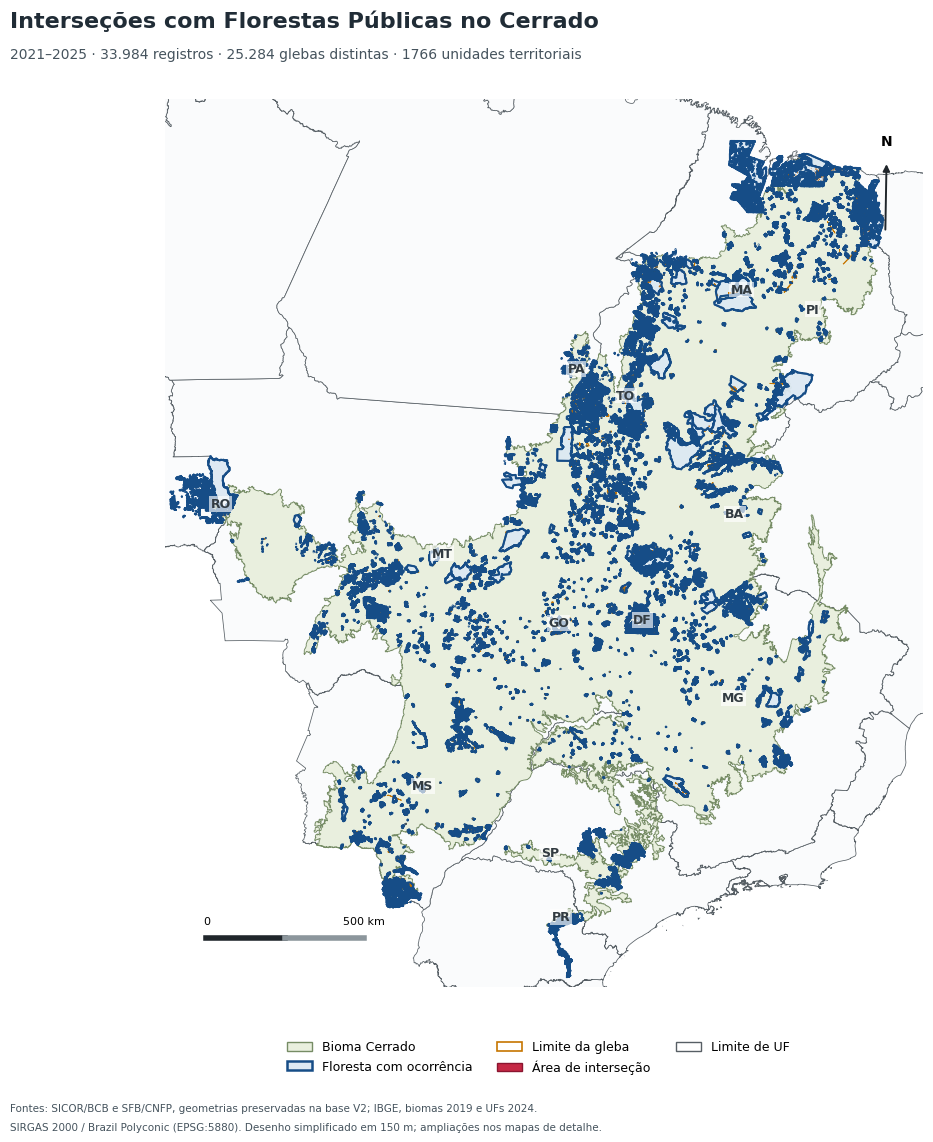

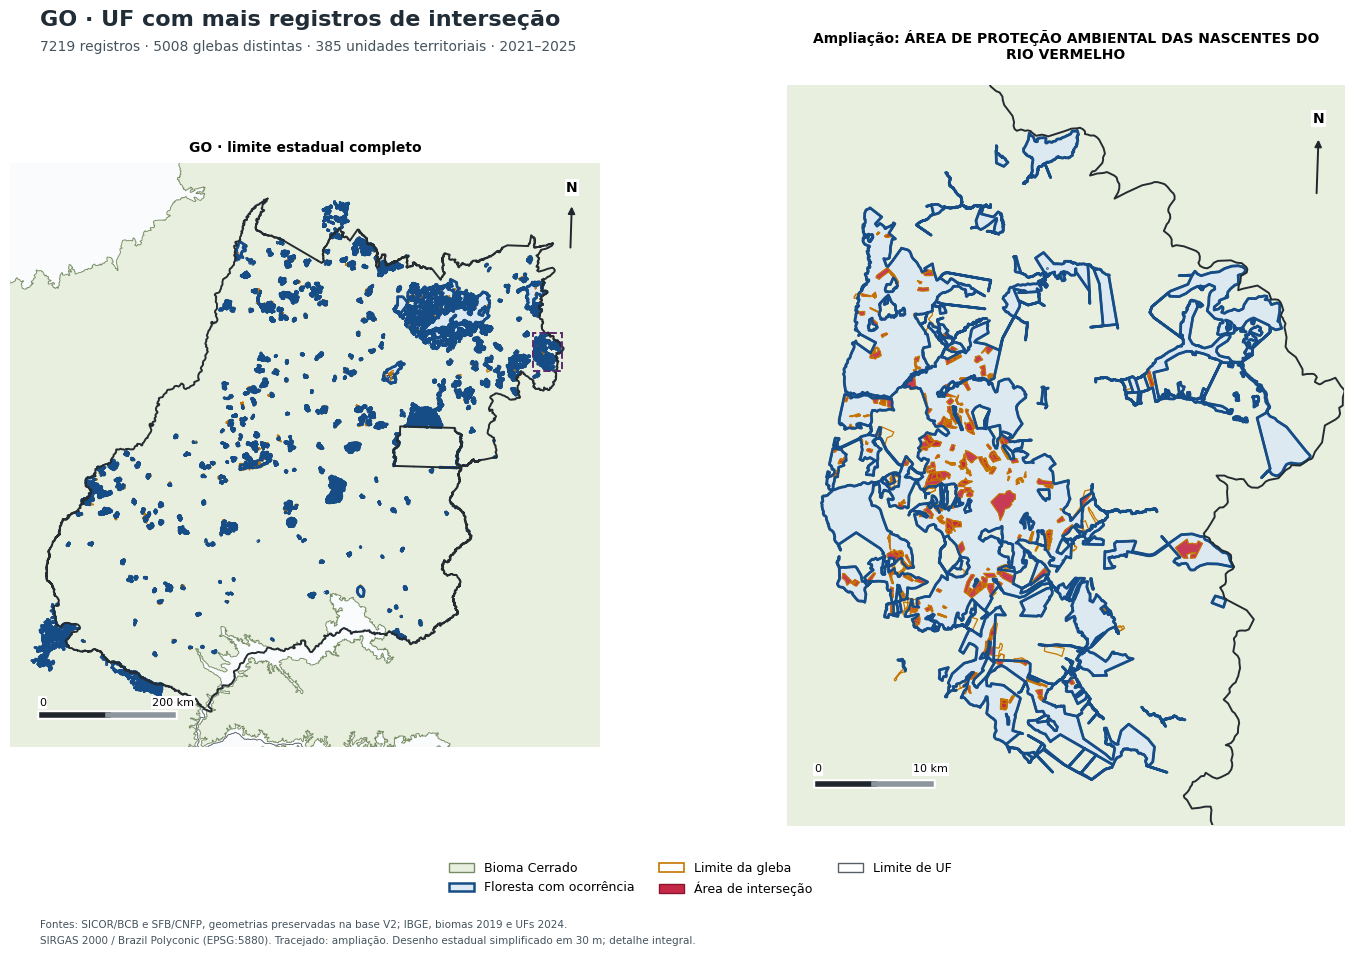

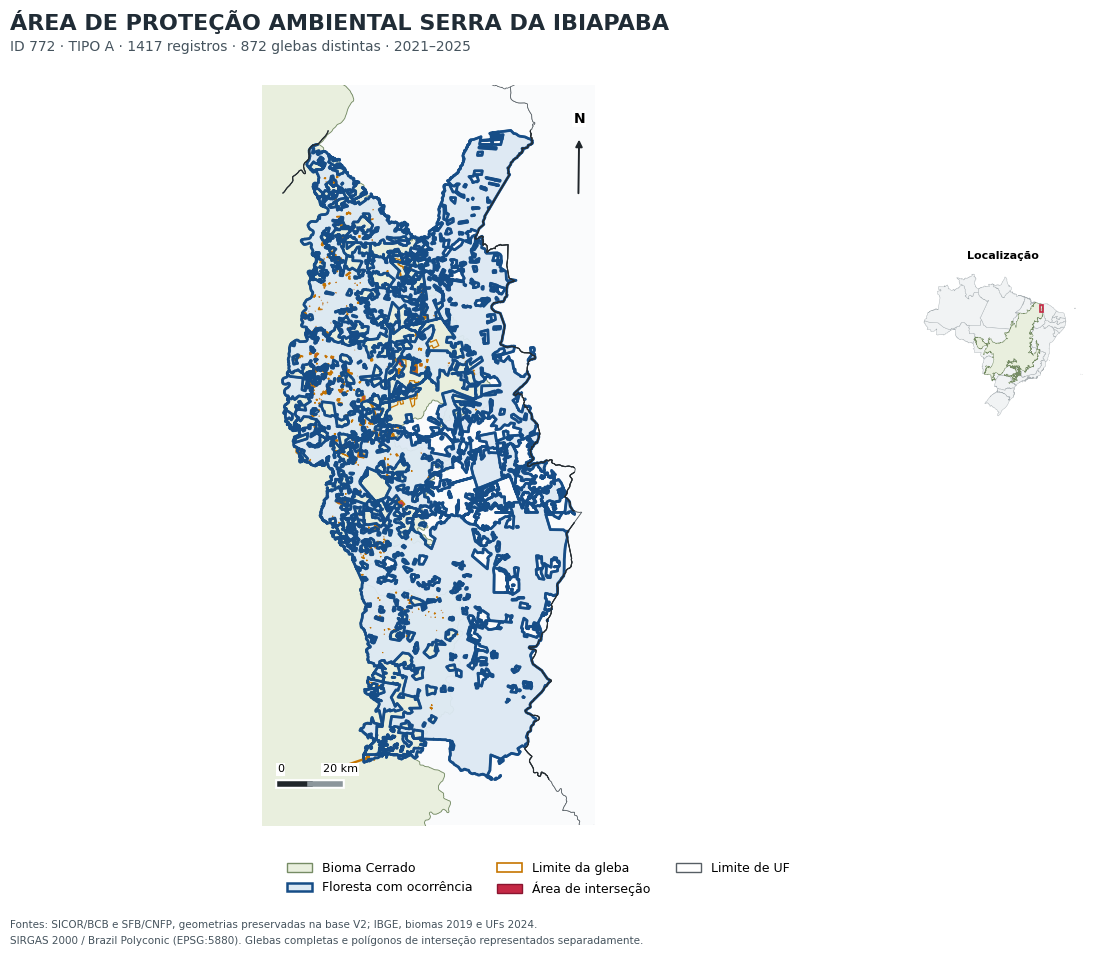

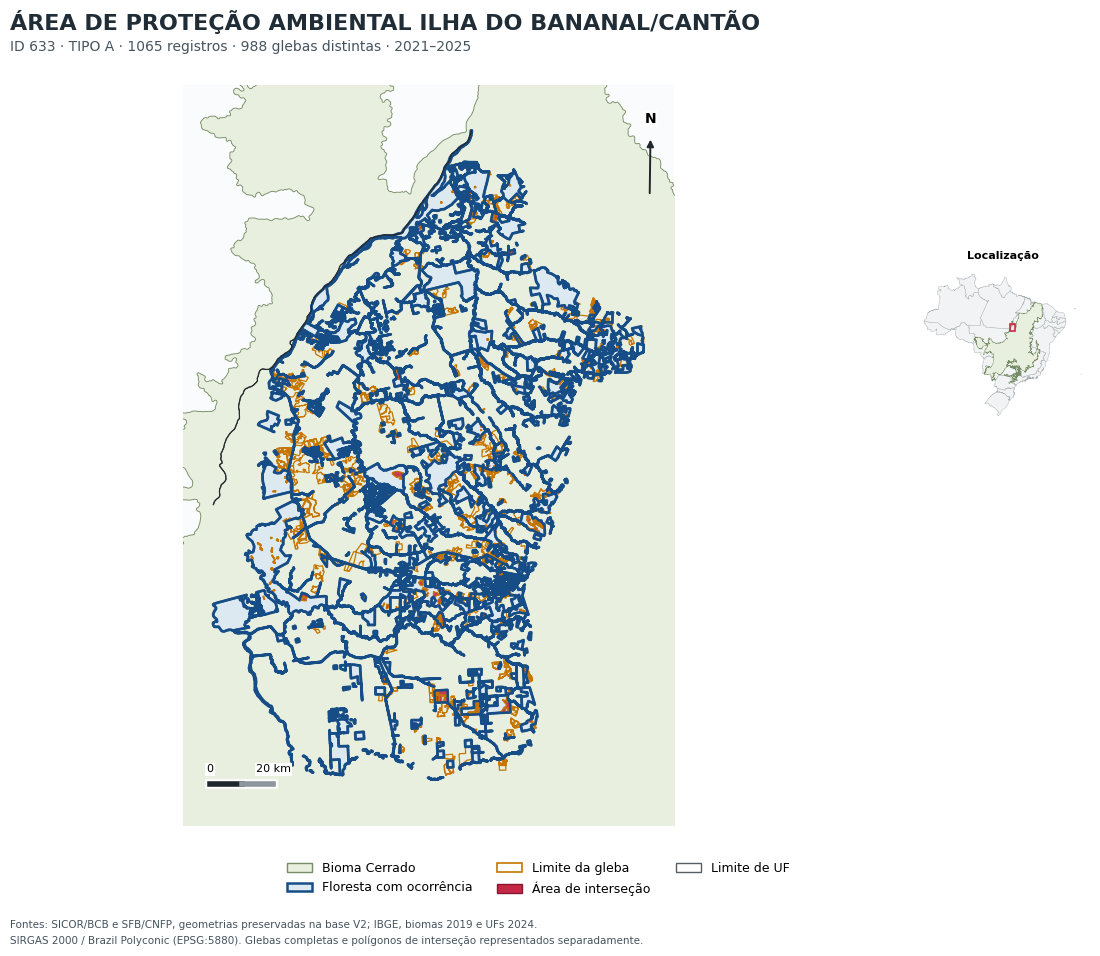

In [8]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titleweight':'bold','savefig.facecolor':'white','svg.fonttype':'none'})
COR_FP='#164D87';COR_GLEBA='#C67500';COR_INTER='#C52845';COR_CERRADO='#E9EFDE';COR_UF='#575F65'
mapas_gerados=[]
para_ll=Transformer.from_crs(CRS_ANALISE,4674,always_xy=True)
para_xy=Transformer.from_crs(4674,CRS_ANALISE,always_xy=True)
geod=Geod(ellps='GRS80')

def serie(geom):return gpd.GeoSeries([geom],crs=CRS_ANALISE)
def enquadrar(ax,bounds,margem=0.07):
    a,b,c,d=map(float,bounds);w=max(c-a,1000);h=max(d-b,1000)
    ax.set_xlim(a-margem*w,c+margem*w);ax.set_ylim(b-margem*h,d+margem*h)
    ax.set_aspect('equal');ax.set_axis_off()

def perto(z,bounds):
    ids=z.sindex.query(box(*bounds),predicate='intersects')
    return z.iloc[ids]

def adornos(ax):
    a,c=ax.get_xlim();b,d=ax.get_ylim();w=c-a;h=d-b
    # Barra horizontal com comprimento calibrado geodesicamente no local.
    x0=a+0.055*w;y0=b+0.055*h
    lo,la=para_ll.transform(x0,y0);lo2,la2=para_ll.transform(x0+0.23*w,y0)
    _,_,dist=geod.inv(lo,la,lo2,la2)
    exp=10**math.floor(math.log10(max(dist,1)))
    length=max(v for v in [1*exp,2*exp,5*exp,10*exp,0.5*exp] if v<=dist)
    dx=0.23*w*length/dist
    ax.plot([x0,x0+dx],[y0,y0],color='white',lw=7,zorder=30)
    ax.plot([x0,x0+dx/2],[y0,y0],color='#20262B',lw=4,zorder=31)
    ax.plot([x0+dx/2,x0+dx],[y0,y0],color='#8C969C',lw=4,zorder=31)
    txt=f'{length/1000:g} km' if length>=1000 else f'{length:g} m'
    ax.text(x0,y0+0.016*h,'0',fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    ax.text(x0+dx,y0+0.016*h,txt,fontsize=8,zorder=32,ha='center',bbox=dict(fc='white',ec='none',pad=1))
    # Norte verdadeiro no ponto de implantação da seta.
    nx=a+0.95*w;ny=b+0.85*h;lon,lat=para_ll.transform(nx,ny)
    xx,yy=para_xy.transform(lon,lat+0.1);vx=xx-nx;vy=yy-ny;norm=math.hypot(vx,vy)
    ex=nx+vx/norm*h*0.08;ey=ny+vy/norm*h*0.08
    ax.annotate('',xy=(ex,ey),xytext=(nx,ny),arrowprops=dict(arrowstyle='-|>',color='#20262B',lw=1.4),zorder=35)
    ax.text(ex,ey+0.015*h,'N',ha='center',va='bottom',weight='bold',fontsize=10,zorder=35,bbox=dict(fc='white',ec='none',pad=1))

def desenhar(ax,territorio_ids,gleba_ids,ocorrencias,bounds,escala='geral',estado=None):
    a,b,c,d=bounds;w=max(c-a,1000);h=max(d-b,1000)
    janela=box(a-.10*w,b-.10*h,c+.10*w,d+.10*h)
    bg=perto(ufs,janela.bounds).copy()
    bg.geometry=bg.geometry.intersection(janela)
    bg.plot(ax=ax,facecolor='#FAFBFC',edgecolor=COR_UF,linewidth=0.55,zorder=0)
    contexto=cerrado.intersection(janela)
    if not contexto.is_empty:serie(contexto).plot(ax=ax,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.65,zorder=1)
    if escala=='geral':
        ts=territorios.loc[territorios.unidade.isin(territorio_ids)];gs=glebas.loc[glebas.gleba.isin(gleba_ids)]
    else:
        tolerancia=SIMPLIFICACAO_ESTADO_M if escala=='estado' else 0
        ts=carregar_geometrias('territorio',territorio_ids,tolerancia)
        gs=carregar_geometrias('gleba',gleba_ids,tolerancia)
    # Cópias sobrepostas desenhadas uma vez; as contagens continuam usando todas as linhas.
    ocorrencias=ocorrencias[['geometry']].drop_duplicates('geometry').copy()
    if escala in ['geral','estado']:
        tol=SIMPLIFICACAO_GERAL_M if escala=='geral' else SIMPLIFICACAO_ESTADO_M
        ocorrencias.geometry=ocorrencias.geometry.simplify(tol,preserve_topology=True)
    if not ts.empty:ts.plot(ax=ax,facecolor='#DDE9F3',edgecolor=COR_FP,linewidth=1.5 if escala=='geral' else 2.0,alpha=0.95,zorder=3)
    if not ocorrencias.empty:ocorrencias.plot(ax=ax,facecolor=COR_INTER,edgecolor='#8A1530',linewidth=0.35,alpha=0.90,zorder=5,rasterized=True)
    if not gs.empty:gs.boundary.plot(ax=ax,color=COR_GLEBA,linewidth=0.65 if escala=='geral' else 0.9,zorder=6,rasterized=True)
    # Redesenha o contorno do território sobre as interseções.
    if not ts.empty:ts.boundary.plot(ax=ax,color=COR_FP,linewidth=1.2 if escala=='geral' else 1.65,zorder=7)
    if estado is not None:serie(estado).boundary.plot(ax=ax,color='#252C31',linewidth=1.4,zorder=7)
    enquadrar(ax,bounds);adornos(ax)

handles=[Patch(facecolor=COR_CERRADO,edgecolor='#768C65',label='Bioma Cerrado'),
         Patch(facecolor='#DDE9F3',edgecolor=COR_FP,linewidth=1.8,label='Floresta com ocorrência'),
         Patch(facecolor='none',edgecolor=COR_GLEBA,linewidth=1.2,label='Limite da gleba'),
         Patch(facecolor=COR_INTER,edgecolor='#8A1530',label='Área de interseção'),
         Patch(facecolor='none',edgecolor=COR_UF,linewidth=1,label='Limite de UF')]

def finalizar(fig,nome,titulo,subtitulo,nota=''):
    fig.suptitle(titulo,x=0.06,y=0.965,ha='left',fontsize=16,weight='bold',color='#202C36')
    fig.text(0.06,0.924 if '\n' not in titulo else 0.89,subtitulo,ha='left',fontsize=10,color='#45535D')
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(0.5,0.068),ncol=3,frameon=False,fontsize=9)
    fonte='Fontes: SICOR/BCB e SFB/CNFP, geometrias preservadas na base V2; IBGE, biomas 2019 e UFs 2024.'
    if ARQUIVO_UFS or ARQUIVO_BIOMAS:fonte='Fontes: SICOR/BCB e SFB/CNFP (base V2); '+FONTE_BIOMAS+'; '+FONTE_UFS+'.'
    fig.text(0.06,0.047,fonte,fontsize=7.5,color='#45535D')
    fig.text(0.06,0.031,'SIRGAS 2000 / Brazil Polyconic (EPSG:5880). '+nota,fontsize=7.5,color='#45535D')
    fig.subplots_adjust(left=0.04,right=0.97,bottom=0.15,top=0.89 if '\n' not in titulo else 0.845)
    for ext in FORMATOS:fig.savefig(SAIDA/'mapas'/f'{nome}.{ext}',dpi=DPI)
    mapas_gerados.append({'arquivo':nome,'titulo':titulo,'subtitulo':subtitulo,'nota':nota})
    if MOSTRAR_FIGURAS:plt.show()
    plt.close(fig)

fig,ax=plt.subplots(figsize=(12,12))
desenhar(ax,territorios.unidade,glebas.gleba,x,cerrado.bounds)
for _,u in ufs.loc[ufs.intersects(cerrado)].iterrows():
    pt=u.geometry.intersection(cerrado).representative_point()
    ax.text(pt.x,pt.y,u.UF,fontsize=9,weight='bold',color='#323B41',ha='center',zorder=20,
            bbox=dict(fc='white',ec='none',alpha=0.65,pad=1))
finalizar(fig,'01_cerrado_florestas_contornos_reforcados','Interseções com Florestas Públicas no Cerrado',
          f"2021–2025 · {len(x):,} registros · {len(glebas):,} glebas distintas · {len(territorios)} unidades territoriais".replace(',','.'),
          f'Desenho simplificado em {SIMPLIFICACAO_GERAL_M} m; ampliações nos mapas de detalhe.')

# Estado completo à esquerda e ampliação do território com mais registros nesse estado à direita.
z=xuf.loc[xuf.UF.eq(UF_TOP)].copy();estado=ufs.loc[ufs.UF.eq(UF_TOP)].geometry.iloc[0]
rank_local=z.groupby('unidade').linha.nunique().rename('n').reset_index().merge(territorios[['unidade','nome']],on='unidade')
top_local=rank_local.sort_values(['n','nome','unidade'],ascending=[False,True,True]).iloc[0].unidade
zl=z.loc[z.unidade.eq(top_local)];territorio_local=carregar_geometrias('territorio',[top_local]).iloc[0]
gl_local=carregar_geometrias('gleba',zl.gleba)
bdet=gpd.GeoSeries([territorio_local.geometry,*gl_local.geometry],crs=CRS_ANALISE).total_bounds
fig,axs=plt.subplots(1,2,figsize=(15,10),gridspec_kw={'width_ratios':[1,1.15]})
desenhar(axs[0],z.unidade.unique(),z.gleba.unique(),z,estado.bounds,'estado',estado)
desenhar(axs[1],[top_local],zl.gleba.unique(),zl,bdet,'detalhe',estado)
axs[0].set_title(f'{UF_TOP} · limite estadual completo',fontsize=10,pad=8)
axs[1].set_title('Ampliação: '+'\n'.join(textwrap.wrap(territorio_local['nome'],width=44)),fontsize=10,pad=8)
a,b,c,e=bdet;axs[0].add_patch(Rectangle((a,b),c-a,e-b,fill=False,edgecolor='#5B296F',linewidth=1.4,linestyle='--',zorder=25))
finalizar(fig,'02_uf_mais_casos_com_ampliacao',f'{UF_TOP} · UF com mais registros de interseção',
          f'{z.linha.nunique()} registros · {z.gleba.nunique()} glebas distintas · {z.unidade.nunique()} unidades territoriais · 2021–2025',
          f'Tracejado: ampliação. Desenho estadual simplificado em {SIMPLIFICACAO_ESTADO_M} m; detalhe integral.')

for pos,ident in enumerate(TOP_TERRITORIOS,1):
    t=carregar_geometrias('territorio',[ident]).iloc[0];zi=x.loc[x.unidade.eq(ident)]
    gi=carregar_geometrias('gleba',zi.gleba)
    limites=gpd.GeoSeries([t.geometry,*gi.geometry],crs=CRS_ANALISE).total_bounds
    fig=plt.figure(figsize=(12,10));ax=fig.add_subplot(1,5,(1,4))
    desenhar(ax,[ident],gi.gleba,zi,limites,'detalhe')
    # Limites estaduais, quando presentes no enquadramento, sempre visíveis.
    limites_uf=perto(ufs,limites).boundary.intersection(box(*limites))
    limites_uf=limites_uf.loc[~limites_uf.is_empty]
    if not limites_uf.empty:limites_uf.plot(ax=ax,color='#252C31',linewidth=0.8,zorder=7)
    # Miniatura em espaço próprio, fora do mapa principal e da seta norte.
    # O painel principal de detalhe utiliza as geometrias integrais.
    en=fig.add_axes([0.815,0.50,0.145,0.26])
    ufs.geometry.simplify(1500,preserve_topology=True).plot(ax=en,facecolor='#F1F3F4',edgecolor='#AAB1B5',linewidth=0.3)
    serie(cerrado.simplify(1500,preserve_topology=True)).plot(ax=en,facecolor=COR_CERRADO,edgecolor='#768C65',linewidth=0.3)
    # Retângulo de localização no Brasil; não representa a área da gleba.
    a,b,c,e=limites;en.add_patch(Rectangle((a,b),max(c-a,80000),max(e-b,80000),fill=False,edgecolor=COR_INTER,linewidth=1.2))
    en.set_axis_off();en.set_title('Localização',fontsize=8)
    m=por_territorio.loc[por_territorio.unidade.eq(ident)].iloc[0]
    titulo='\n'.join(textwrap.wrap(t['nome'],width=65))
    finalizar(fig,f'{pos+2:02d}_floresta_{re.sub(r"[^A-Za-z0-9_-]","_",str(ident))}_detalhe',titulo,
       f"ID {ident} · {t.tipo} · {m.registros} registros · {m.glebas} glebas distintas · 2021–2025",
       'Glebas completas e polígonos de interseção representados separadamente.')


## 8. Exportar tabelas e informações para o texto
A tabela integral, com 1.766 unidades na V2 de referência, é exportada em CSV, Excel e HTML. Também é produzida uma versão com as 20 primeiras unidades para facilitar a apresentação no corpo do capítulo; ela é explicitamente parcial, e não substitui o arquivo completo.

In [9]:
def br(v,casas=0):
    if pd.isna(v):return 'Não informado'
    return f'{float(v):,.{casas}f}'.replace(',','X').replace('.',',').replace('X','.')

cols=['unidade','nome','tipo','uf_territorio','registros','glebas','refs','area_acumulada_ha','area_uniao_ha']
tab=por_territorio[cols].copy()
# O total recalcula união e contagens distintas no conjunto completo.
tot={'unidade':'TOTAL','nome':'Conjunto completo','tipo':'—','uf_territorio':'—',**geral}
tab=pd.concat([tab,pd.DataFrame([{k:tot[k] for k in cols}])],ignore_index=True)
for c in ['registros','glebas','refs']:tab[c]=tab[c].map(br)
for c in ['area_acumulada_ha','area_uniao_ha']:tab[c]=tab[c].map(lambda v:br(v,2))
tab.columns=['ID interno','Floresta pública','Tipo','UF informada','Registros','Glebas distintas','REF_BACEN distintos','Área acumulada (ha)','Área da união (ha)']
nota=('Fonte: elaborado pelo autor com base nas interseções SICOR × SFB/CNFP, versão 2, e conferências desta execução. '
      'Registros correspondem às linhas originais. Glebas e referências podem ocorrer em várias unidades. '
      'IDs internos distintos são preservados, inclusive para nomes iguais ou não informados. '
      'A união global e as contagens distintas são recalculadas, não somadas entre unidades. Áreas em EPSG:5880. '
      'UF informada: atributo FP_UF, que pode diferir da localização das interseções.')
def tabela_html(t,titulo,arquivo,nota_extra=''):
    from html import escape
    html=('<!doctype html><html lang="pt-BR"><meta charset="utf-8"><title>'+escape(titulo)+
      '</title><style>body{font:12px Arial;margin:24px}table{border-collapse:collapse;width:100%}'
      'th,td{padding:6px;border:1px solid #bbb}th{background:#e4edf4}p{line-height:1.5}'
      '@media print{thead{display:table-header-group}tr{break-inside:avoid}@page{size:A4 landscape;margin:15mm}}</style>'
      '<h2>'+escape(titulo)+'</h2>'+t.to_html(index=False,escape=True,border=0)+'<p>'+escape(nota+' '+nota_extra)+'</p></html>')
    (SAIDA/'tabelas'/arquivo).write_text(html,encoding='utf-8')
tabela_html(tab,'Interseções por floresta pública — Cerrado, 2021–2025','tabela_completa_para_word.html')
tabela_html(tab.iloc[:-1].head(20),'20 florestas com mais registros — Cerrado, 2021–2025',
            'tabela_20_primeiras_para_word.html','Tabela parcial: o conjunto completo está no arquivo complementar; não representa o total da base.')
csv(por_territorio.head(20),'20_florestas_com_mais_registros.csv')
controle_rank_unidades=pd.DataFrame({'unidade':['772','633'],'registros_resumo_v2':[1417,1065],
    'nome_resumo_v2':['APA SERRA DA IBIAPABA','APA ILHA DO BANANAL/CANTÃO']})
controle_rank_unidades=controle_rank_unidades.merge(por_territorio[['unidade','nome','registros','posicao']],on='unidade',how='left')
controle_rank_unidades['diferenca']=controle_rank_unidades.registros-controle_rank_unidades.registros_resumo_v2
csv(controle_rank_unidades,'conferencia_unidades_destaque_v2.csv')

with pd.ExcelWriter(SAIDA/'tabelas'/'Totais_Florestas_Publicas_5_5_3.xlsx',engine='openpyxl') as writer:
    for name,z in [('Por floresta - completo',por_territorio),('20 primeiras',por_territorio.head(20)),
      ('Total geral',pd.DataFrame([geral])),('Ranking UFs',por_uf),('Por tipo',por_tipo),
      ('Identificacao',auditoria_nomes),('Auditoria UF',auditoria_uf),('Conferencia areas UF',conferencia_uf),
      ('Conferencia ranking UF',controle_rank_uf),('Conferencia destaques',controle_rank_unidades),('Conferencia V2',conferencia),('Todas unidades V2',controle_unidades)]:
        z.to_excel(writer,sheet_name=name,index=False)
        ws=writer.sheets[name];ws.freeze_panes='A2';ws.auto_filter.ref=ws.dimensions
        from openpyxl.styles import Font,PatternFill
        for cell in ws[1]:cell.font=Font(bold=True,color='FFFFFF');cell.fill=PatternFill('solid',fgColor='164D87')
        for column in ws.columns:
            letter=column[0].column_letter
            ws.column_dimensions[letter].width=min(52,max(14,max(len(str(c.value or '')) for c in column)+2))
            if any(t in str(column[0].value) for t in ['area_','soma_valores']):
                for cell in column[1:]:cell.number_format='#,##0.00'
    pd.DataFrame({'Notas':[nota,
      'Soma_valores_linhas: soma dos valores das linhas; não é montante exclusivo contratado, desembolsado ou irregular.',
      'Ranking UF: área positiva da interseção em cada UF; cada registro conta uma vez por UF.',
      'Casos e seleção de florestas: quantidade de registros, não área nem número de produtores.',
      'Tipo reproduz FP_TIPO. Não foram inferidas situação, destinação ou esfera administrativa.',
      'Área da união considera apenas as interseções; não é a área total da floresta.',
      'Cálculos integrais. Simplificação de geometrias apenas para desenho geral e estadual.'
    ]}).to_excel(writer,sheet_name='Leia-me',index=False)

selecionadas=por_territorio.head(NUMERO_TERRITORIOS_DETALHE)
texto=(f"Foram examinados {br(geral['registros'])} registros, associados a {br(geral['glebas'])} glebas distintas, "
       f"{br(geral['territorios'])} unidades da base de florestas públicas e {br(geral['refs'])} referências BACEN distintas. "
       f"A área acumulada foi de {br(geral['area_acumulada_ha'],2)} ha e a união geométrica de {br(geral['area_uniao_ha'],2)} ha. "
       f"A soma dos valores presentes nas linhas foi de R$ {br(geral['soma_valores_linhas'],2)}.\n\n"
       f"A UF selecionada para o mapa foi {UF_TOP}, com {br(por_uf.iloc[0].registros)} registros. "
       "A seleção contou cada linha original uma vez por UF com área positiva de interseção.\n\n"
       "As unidades selecionadas para os mapas de detalhe, em ordem decrescente de registros, foram:\n")
for _,r in selecionadas.iterrows():
    texto+=f"- {r['nome']} (ID {r.unidade}; {r.tipo}; UF do atributo: {r.uf_territorio}): {br(r.registros)} registros, {br(r.glebas)} glebas, {br(r.refs)} REF_BACEN distintos e {br(r.area_uniao_ha,2)} ha de união.\n"
texto+=('\nA tabela integral discrimina os totais por ID de floresta pública e preserva unidades com nomes iguais ou sem denominação. '
        'O mapa geral mostra os limites das florestas em azul forte; o mapa estadual inclui uma ampliação; '
        'os dois mapas individuais distinguem o limite da floresta, as glebas completas e as áreas de interseção. '
        'Somente unidades com ocorrência na amostra são representadas.\n\n'
        'As contagens expressam ocorrências de triagem espacial. A soma financeira está sujeita à repetição de valores nas linhas e '
        'não equivale ao crédito exclusivo das áreas intersectadas. Tipo é o atributo literal FP_TIPO; situação, destinação e esfera '
        'administrativa não foram inferidas. O período 2021–2025 refere-se a ANO_BASE da base analisada.\n')
texto+=(f"\nA soma estadual é de {br(por_uf.registros.sum())} registros; {br(len(linhas_multiuf))} linha(s) aparecem em mais de uma UF. "
        "O total global permanece sendo o número de linhas originais. Os recortes estaduais usam a malha IBGE 2024. "
        "Diferenças em relação aos resumos anteriores ficam nas tabelas de conferência.\n")
if not conferencia.confere.all():texto+='\nATENÇÃO: existem divergências em relação aos totais V2 de referência; consulte conferencia_com_texto_5_5_3.csv antes de revisar o subcapítulo.\n'
(SAIDA/'resultados_para_resposta_ao_orientador.txt').write_text(texto,encoding='utf-8')
legendas=[]
for m in mapas_gerados:
    legendas.append(m['arquivo']+'\n'+m['titulo'].replace('\n',' ')+' — '+m['subtitulo']+'.\n'+m['nota']+
       '\nFonte: elaborado pelo autor com base no SICOR/BCB e nos limites do SFB/CNFP preservados na versão 2; '+FONTE_BIOMAS+'; '+FONTE_UFS+'.\n')
(SAIDA/'legendas_das_figuras.txt').write_text('\n'.join(legendas),encoding='utf-8')
observacoes=[
 'Seleção das duas florestas e da UF: maior quantidade de registros; não maior área física.',
 'Unidade territorial: FP_ID_INTERNO. Nomes iguais, S/NOME_GLEBA e outras denominações genéricas não foram fundidos.',
 'Os limites completos das florestas são os preservados na V2, não uma base territorial atualizada.',
 'A UF do atributo FP_UF não foi alterada; diferenças para a localização espacial são documentadas.',
 'A tabela completa é adequada a apêndice. A versão de 20 unidades é parcial e precisa ser identificada como tal.',
 'O arquivo de origem não foi recortado novamente pelo Cerrado: os resultados dizem respeito ao universo espacial da V2 fornecida.',
 'Contagens distintas e áreas de união não são aditivas entre florestas; a linha TOTAL foi recalculada no conjunto inteiro.',
 'A classificação Tipo A/B foi preservada, sem deduzir situação jurídica, destinação ou esfera administrativa.',
 'As geometrias de cálculo e de detalhe são integrais. Somente o desenho geral e estadual foi simplificado.',
 'O cache armazena geometrias únicas para desenho e todas as linhas de interseção; não elimina registros administrativos.',
 'Não há comprovação automática de desconformidade. É necessária avaliação administrativa e temporal de cada caso.'
]
(SAIDA/'observacoes_para_revisao_do_subcapitulo.txt').write_text('\n'.join(observacoes),encoding='utf-8')
print(texto)


Foram examinados 33.984 registros, associados a 25.284 glebas distintas, 1.766 unidades da base de florestas públicas e 25.864 referências BACEN distintas. A área acumulada foi de 445.302,34 ha e a união geométrica de 232.002,78 ha. A soma dos valores presentes nas linhas foi de R$ 12.321.219.185,59.

A UF selecionada para o mapa foi GO, com 7.219 registros. A seleção contou cada linha original uma vez por UF com área positiva de interseção.

As unidades selecionadas para os mapas de detalhe, em ordem decrescente de registros, foram:
- ÁREA DE PROTEÇÃO AMBIENTAL SERRA DA IBIAPABA (ID 772; TIPO A; UF do atributo: PI): 1.417 registros, 872 glebas, 820 REF_BACEN distintos e 4.714,32 ha de união.
- ÁREA DE PROTEÇÃO AMBIENTAL ILHA DO BANANAL/CANTÃO (ID 633; TIPO A; UF do atributo: TO): 1.065 registros, 988 glebas, 653 REF_BACEN distintos e 13.829,48 ha de união.

A tabela integral discrimina os totais por ID de floresta pública e preserva unidades com nomes iguais ou sem denominação. O mapa

## 9. Metadados, ZIP e pasta dos resultados
Compartilhe o ZIP ou a pasta desta execução para a reescrita do subcapítulo. O cache reduzido fica na pasta `_cache`, fora do ZIP. Se a conferência indicar divergências, utilize as tabelas de diagnóstico antes de substituir os números do texto.

In [10]:
metadados={'execucao_utc':datetime.now(timezone.utc).isoformat(),'origens':ORIGENS,'crs_wkt':CRS_WKT,'crs_calculo':CRS_ANALISE,
 'fontes_contexto':{'ufs':FONTE_UFS,'biomas':FONTE_BIOMAS},'colunas':C,'anos':ANOS,'deduplicacao_analitica':False,
 'unidade_caso':'Linha original da base espacial V2','criterio_selecao':'Quantidade de registros decrescente; desempate por nome/ID ou sigla UF',
 'uf_selecionada':UF_TOP,'territorios_selecionados':TOP_TERRITORIOS,'totais':{k:float(v) if isinstance(v,(np.floating,np.integer)) else v for k,v in geral.items()},
 'contexto_territorios':'Somente florestas com ocorrência; limites da V2. Desenho geral/estadual simplificado, detalhe integral'
 ,'simplificacao_desenho_m':{'geral':SIMPLIFICACAO_GERAL_M,'estado':SIMPLIFICACAO_ESTADO_M,'detalhe':0}
 ,'cache':str(BANCO),'identificacao_base':'caminho, bytes e mtime_ns; não é hash integral','mapas':mapas_gerados,'coluna_nome':C['nome'],'referencia_rank_unidades':{'772':1417,'633':1065},'divergencias_uf_atributo':int((~auditoria_uf.uf_informada_inclui_uf_espacial).sum()),
 'diferenca_corte_estadual_ha':residuo,'confere_totais_referencia':bool(conferencia.confere.all()),
 'versoes':{'python':platform.python_version(),'pandas':pd.__version__,'geopandas':gpd.__version__,'shapely':shapely.__version__}}
(SAIDA/'metadados.json').write_text(json.dumps(metadados,ensure_ascii=False,indent=2),encoding='utf-8')
zip_final=SAIDA/'Resultados_Florestas_Publicas_5_5_3.zip'
with zipfile.ZipFile(zip_final,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SAIDA.rglob('*')):
        if p.is_file() and p!=zip_final:z.write(p,arcname=str(p.relative_to(SAIDA)))
print('Resultados salvos em:',SAIDA)
print('ZIP:',zip_final)
if BAIXAR_ZIP:
    from google.colab import files
    files.download(str(zip_final))


Resultados salvos em: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_florestas_publicas_5_5_3/20260918_124912_005341
ZIP: /content/drive/MyDrive/Colab Notebooks/fluxo/Envio/Arquivos gerados e relatorios/complementos_florestas_publicas_5_5_3/20260918_124912_005341/Resultados_Florestas_Publicas_5_5_3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Como usar os resultados na dissertação

- **Tabela:** `tabelas/tabela_completa_para_word.html` abre no navegador ou no Word; a planilha inclui a tabela integral e os rankings. Para o corpo do capítulo, pode-se usar a tabela das 20 primeiras unidades e remeter o conjunto completo ao apêndice.
- **Figuras:** `mapas/01_cerrado_florestas_contornos_reforcados`, `02_uf_mais_casos_com_ampliacao` e os dois arquivos de detalhe. As legendas editáveis ficam em `legendas_das_figuras.txt`, sem impor numeração definitiva ao capítulo.
- **Texto:** `resultados_para_resposta_ao_orientador.txt` apresenta os totais efetivamente calculados e os critérios de seleção. `observacoes_para_revisao_do_subcapitulo.txt` explica as limitações.
- **Conferência:** totais gerais, áreas por linha, ranking estadual, atributos e ocorrências em mais de uma UF ficam documentados. Os Tipos A/B não substituem a identificação de situação, destinação ou esfera administrativa.

As interseções constituem triagem espacial. A soma de valores nas linhas não representa necessariamente crédito exclusivo dessas áreas ou concessões irregulares. A união elimina repetição geométrica; registros administrativos e geometrias continuam sendo unidades de análise diferentes.